# SO101 chess: simulation → real arm

Train on simulation only, then evaluate the same world-model controller on a LeRobot SO101 with a wrist camera. The task is one chess piece moved between reachable squares on an otherwise empty board.

This notebook defaults to a **small, motor-free smoke experiment**. Its smoke outputs validate the workflow, not zero-shot manipulation performance. All reusable code lives in `torch_world.sim2real`. See the [setup and calibration guide](../../docs/guides/sim2real.md).

Install simulation dependencies with `uv pip install -e '.[sim2real,notebooks]'`. Hardware uses Python 3.12+ and `uv pip install -e '.[so101,notebooks]'`. First simulation use downloads the pinned robot assets; the smoke model does not download pretrained weights.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

import torch_world
from torch_world.planning import CEM, LeWAMPlanner
from torch_world.sim2real import (
    Calibration,
    SO101Chess,
    SO101Robot,
    WorldModelPolicy,
    capture_wrist_camera,
    label_trial,
    load_checkpoint,
    load_goal,
    make_adapter,
    reference_setup,
    render_reference_pose,
    run_experiment,
    run_trial,
    save_goal,
    scripted_episode,
    simulation_gate,
)
from torch_world.sim2real.experiment import save_video

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})
torch.set_num_threads(2)
SMOKE = True
MODEL = "lewam"  # "lewam", "lewm", "dinowm", or "robojepa"
LEWAM_CHUNK_SIZE = 8
LEWAM_SAMPLES = 1  # Direct action policy; >1 ranks proposals using learned dynamics.
LEWM_PROPRIOCEPTION = True
LEWM_ROLLOUT_STEPS = 8  # Baseline reproduction: False and 1, respectively.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
RUNS = Path("runs/so101-chess")
RUNS.mkdir(parents=True, exist_ok=True)

# Load your measured profile BEFORE training a hardware-bound model.
CALIBRATION_PATH = None  # e.g. Path("runs/my_so101_calibration.json")
calibration = Calibration.load(CALIBRATION_PATH) if CALIBRATION_PATH else None
config, task = reference_setup(size=32 if SMOKE else 140)
RENDER_SIZE = 384 if SMOKE else 512  # Native presentation renders; independent of model input size.
REPO = Path(torch_world.__file__).resolve().parents[1]

# Physical cells remain inactive unless explicitly selected.
ENABLE_HARDWARE = False
CAPTURE_GOAL = False
RUN_PHYSICAL_TRIAL = False
PORT = None  # Your LeRobot follower serial port.
CAMERA_INDEX = 1  # Verify the external camera index before enabling hardware.
GOAL_PATH = RUNS / "real_goal.pt"
print(f"Mode: {'smoke' if SMOKE else 'experiment'} | model: {MODEL} | device: {DEVICE}")

Mode: smoke | model: lewam | device: cpu


## 1. Check the scene and wrist view

The supplied board is **250 × 250 mm**, with a **1 mm panel**. `reference_setup()` uses a white SO101, a wooden chessboard and a wrist camera fitted to the recorded resting image. The border, 15 mm case depth, joint pose and camera mounting are estimates, not verified calibration. The [fit report](assets/rest-view-fit.json) records the landmarks and residuals.

The resting pose is a visual preview only. The scripted demonstration and training start in their working approach pose. Success requires a lifted piece to be released upright inside the destination square, with the gripper withdrawn and the placement settled.

Reachable squares: a1, a2, a3, a4, a5, a6, a7, a8, b1, b2, b3, b4, b5, b6


Scripted reference: {'success': True, 'placed': True, 'distance': 0.0008183613182339704, 'upright': True, 'lifted': True, 'truncated': False, 'piece_position': [0.33115257881513993, 0.03592732392283562, 0.015356338825930736]}


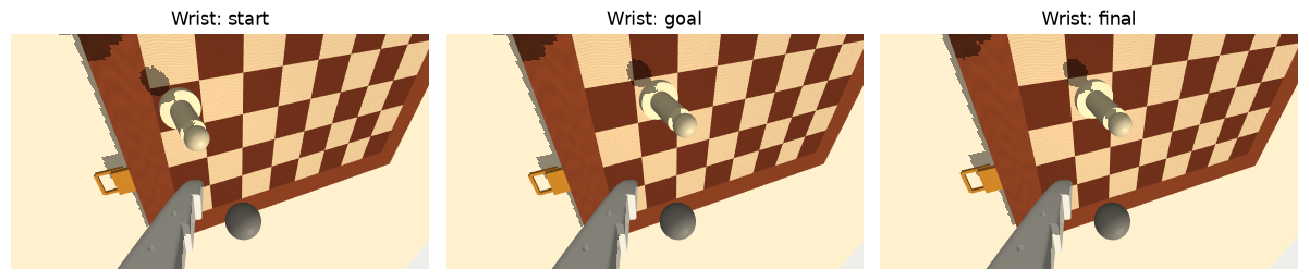

Scripted video: runs/so101-chess/scripted-reference.gif


In [2]:
with SO101Chess(config, task, calibration=calibration) as scene:
    scene.reset(seed=7, source="a4", target="b4")
    print("Reachable squares:", ", ".join(scene.reachable_squares()))
    reference_rgb = render_reference_pose(scene, size=1280)
    mock_calibration = Calibration.from_simulator(scene.model, resolution=(32, 32))

demo = scripted_episode(
    config=config, task=task, source="a4", target="b4", calibration=calibration, render_size=RENDER_SIZE
)
print("Scripted reference:", demo["outcome"])
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, name in zip(axes, ("start", "goal", "final")):
    ax.imshow(demo["views"][name].permute(1, 2, 0), interpolation="none")
    ax.set_title(f"Wrist: {name}")
    ax.axis("off")
plt.tight_layout()
plt.show()
save_video(RUNS / "scripted-reference.gif", demo["frames"], control_dt=config.control_dt)
print("Scripted video:", RUNS / "scripted-reference.gif")

### Recorded real camera observation

The original 1280 × 720 wrist capture was recorded on 15 October 2026 using the external icspring camera, with no motor connection. Compare it with the estimated resting pose below. A visual fit does not replace measured joint readings or camera calibration. Live refresh is disabled by default.

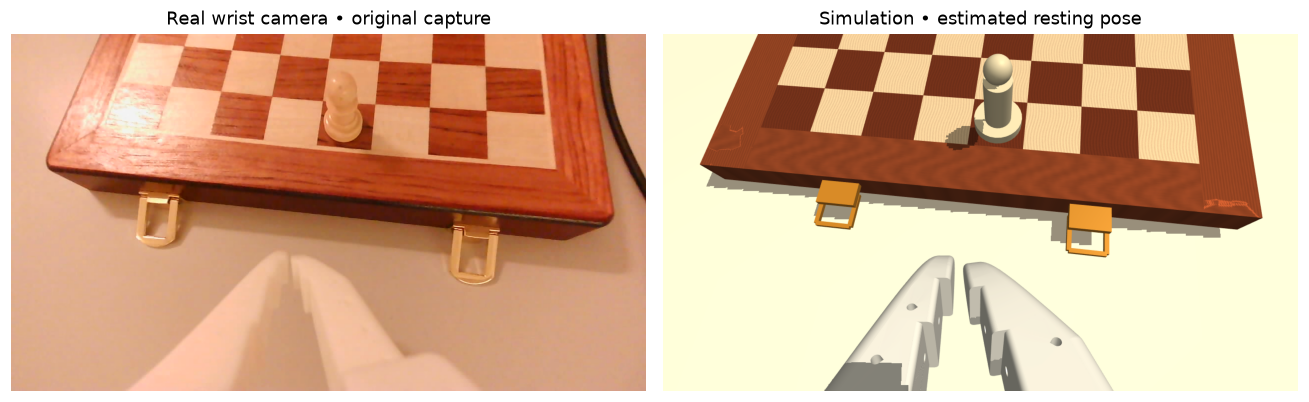

Resting-view fit: Estimated from the supplied resting-pose photo; not verified hand-eye calibration
Board pixel-coordinate RMS: 3.6495679910142664
Estimated resting joints (radians): [-0.15523062697145798, -1.6534048129977812, 1.4558745116946556, 0.7371853018650153, -1.59054506732315]


In [3]:
from PIL import Image as PILImage

reference_path = REPO / "examples/sim2real/assets/wrist-reference.png"
if reference_path.exists():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    with PILImage.open(reference_path) as photo:
        axes[0].imshow(photo)
    axes[0].set_title("Real wrist camera • original capture")
    axes[1].imshow(reference_rgb.permute(1, 2, 0))
    axes[1].set_title("Simulation • estimated resting pose")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    fig.savefig(RUNS / "wrist-reference-comparison.png", bbox_inches="tight")
    plt.show()
fit_report = json.loads((REPO / "examples/sim2real/assets/rest-view-fit.json").read_text())
print("Resting-view fit:", fit_report["status"])
print("Board pixel-coordinate RMS:", fit_report["rms_pixel_coordinate_error"])
print("Estimated resting joints (radians):", fit_report["rest_joints_radians"])

In [4]:
REFRESH_CAMERA = False  # Set True only when you want a fresh camera-only snapshot.
CAMERA_DEVICE = "icspring camera"  # Explicit AVFoundation name; on Linux use /dev/videoN.
if REFRESH_CAMERA:
    camera_path = RUNS / "camera-inspection.png"
    camera_report = capture_wrist_camera(camera_path, device=CAMERA_DEVICE, warmup=2.0)
    display(Image(filename=str(camera_path), width=960))
    print(camera_report)
else:
    print("Stored camera inspection shown above; live refresh disabled. No motors connected.")

Stored camera inspection shown above; live refresh disabled. No motors connected.


## 2. Collect, train and evaluate

Choose LeWAM, LeWM, DINO-WM or RoboJEPA in the configuration cell. The compact CNN recipes are research baselines, not paper-scale reproductions. Non-smoke patch models download DINOv2 features; the RoboJEPA adapter is a DINOv2 variant.

The library collects simulation-only episodes, trains on a separate split, and evaluates learned, scripted and random control on matching seeds. The two-update smoke run checks the software path and cannot establish learning or enable a physical trial. Set `SMOKE=False` to run the larger experiment. CUDA is selected when available; the [guide](../../docs/guides/sim2real.md) also provides Spark CLI commands.

In [5]:
def planner_factory():
    if MODEL == "lewam":
        return LeWAMPlanner(num_samples=LEWAM_SAMPLES)
    limits = torch.tensor([1, 1, 1, config.max_gripper_step], device=DEVICE)
    return CEM(
        horizon=3 if SMOKE else 8,
        action_dim=4,
        num_samples=8 if SMOKE else 16,
        num_elites=2,
        iterations=1,
        bounds=(-limits, limits),
    )


torch.manual_seed(config.seed)
training_adapter = make_adapter(
    MODEL,
    size=config.size,
    smoke=SMOKE,
    proprioception=True if MODEL == "lewam" else LEWM_PROPRIOCEPTION if MODEL == "lewm" else False,
    rollout_steps=LEWM_ROLLOUT_STEPS if MODEL == "lewm" else 1,
    chunk_size=LEWAM_CHUNK_SIZE,
    action_scale=(1, 1, 1, config.max_gripper_step),
)
result = run_experiment(
    adapter=training_adapter,
    config=config,
    task=task,
    calibration=calibration,
    model=MODEL,
    smoke=SMOKE,
    device=DEVICE,
    episodes=2 if SMOKE else 72,
    updates=2 if SMOKE else 3000,
    collect_steps=12 if SMOKE else None,
    evaluation_steps=4 if SMOKE else None,
    evaluation_seeds=tuple(range(10007, 10008 if SMOKE else 10031)),
    output_dir=RUNS,
    planner_factory=planner_factory,
    cache_features=MODEL == "dinowm" and not SMOKE,
    batch_size=16,
)
run_dir = Path(result["run_dir"])
print("Saved experiment:", run_dir)
print("Training losses:", result["losses"][-5:])
print("Held-out loss:", result["heldout_loss"])
for domain, policies in result["evaluation"].items():
    for name, metrics in policies.items():
        print(f"{domain:10s} | {name:8s} | success {metrics['success_rate']:.1%}")

/Users/kcosta/repos/research/oss/pytorch-world/torch_world/sim2real/experiment.py:354: UserWarning: No successful LeWAM demonstrations: the action branch receives no supervision.
  losses = train(


Saved experiment: runs/so101-chess/20261017T222744-09b15d27
Training losses: [0.4584386646747589, 0.39556729793548584]
Held-out loss: 0.24460621178150177
nominal    | learned  | success 0.0%
nominal    | scripted | success 0.0%
nominal    | random   | success 0.0%
randomized | learned  | success 0.0%
randomized | scripted | success 0.0%
randomized | random   | success 0.0%


## 3. Reload and inspect artifacts

Checkpoints include model weights, preprocessing/control settings, task measurements, and the calibration fingerprint. Incompatible settings are rejected. The run directory also contains episode tensors and metadata, metrics, videos, and a completion manifest. Short smoke evaluations are expected to be unsuccessful at completing a full move.

Reloaded: {'kind': 'lewam', 'size': 32, 'history': 3, 'smoke': True, 'encoder': 'cnn', 'chunk_size': 8, 'action_scale': [1, 1, 1, 0.15], 'proprioception': True}


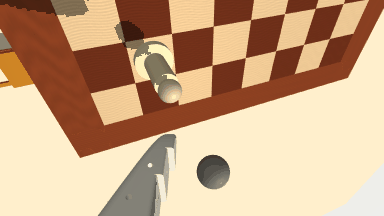

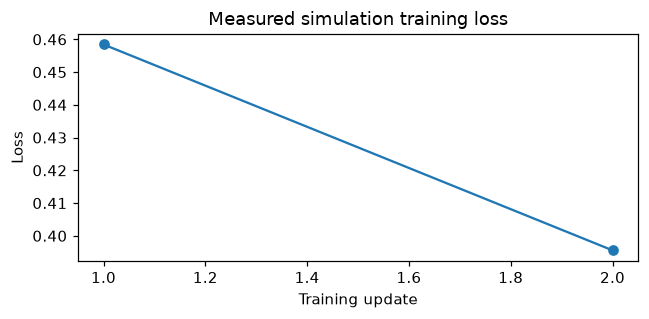

In [6]:
adapter = load_checkpoint(run_dir / "model.pt", config, task, calibration, device=DEVICE)
print("Reloaded:", adapter.recipe)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(1, len(result["losses"]) + 1), result["losses"], marker="o")
ax.set(xlabel="Training update", ylabel="Loss", title="Measured simulation training loss")
plt.tight_layout()
display(Image(filename=str(run_dir / "nominal-learned.gif")))

## 4. Read the recorded simulation results

The archived Spark reports below are separate from this notebook's new smoke run. They contain unsuccessful learned-control experiments; falling training loss did not establish reliable placement. Loss scales differ across models. The guide describes their data, planning budgets and diagnostic limitations.

These reports predate the general delayed-window alignment and calibrated camera-aspect fixes in this module. Rerun training and evaluation to measure those changes. Archived outcomes cannot enable a different checkpoint's hardware trial.

LeWAM direct: 3000 updates; 72 training episodes
  nominal: 0/24 placements, 0 lifted, 24 controller rejections
  randomized: 0/24 placements, 0 lifted, 24 controller rejections
  Simulation progression gate: False
DINO-WM: 3000 updates; 72 training episodes
  nominal: 0/24 placements, 1 lifted, 19 controller rejections
  randomized: 0/24 placements, 1 lifted, 22 controller rejections
  Simulation progression gate: False
LeWM (CNN): 3000 updates; 72 training episodes
  nominal: 0/24 placements, 1 lifted, 10 controller rejections
  randomized: 0/24 placements, 1 lifted, 8 controller rejections
  Simulation progression gate: False
LeWM + state + rollout: 3000 updates; 72 training episodes
  nominal: 0/24 placements, 4 lifted, 14 controller rejections
  randomized: 0/24 placements, 2 lifted, 11 controller rejections
  Simulation progression gate: False


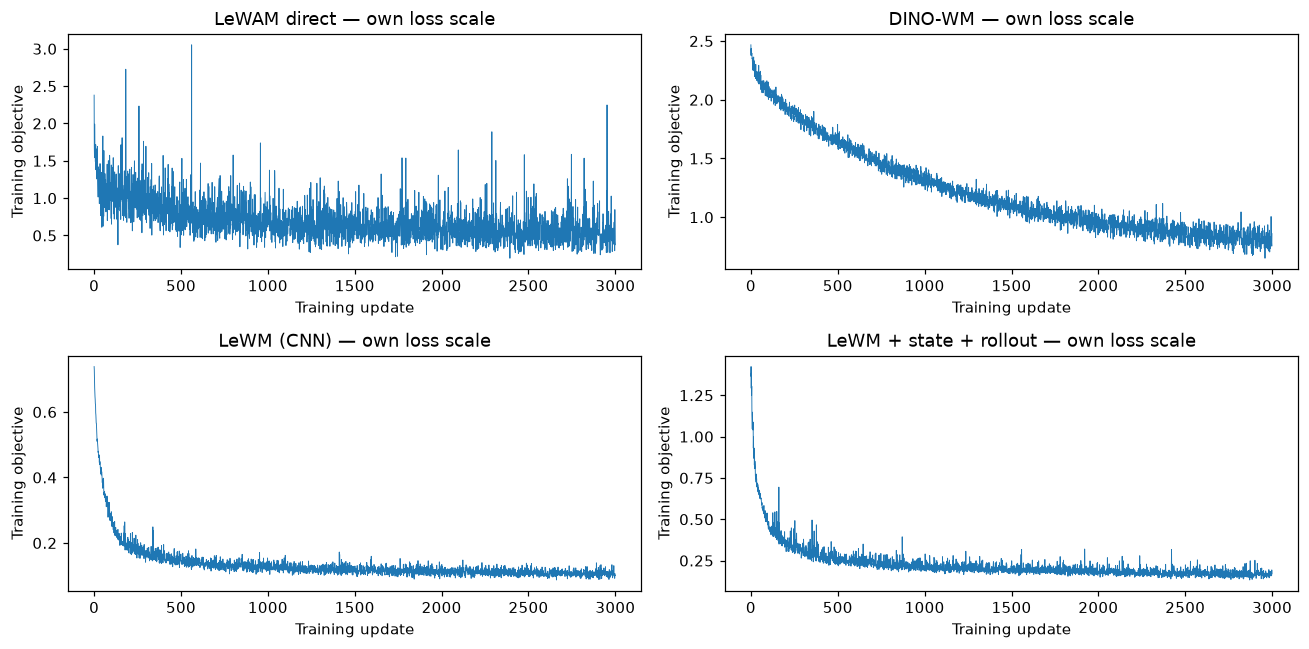

In [7]:
comparison_reports = {
    "LeWAM direct": REPO / "examples/sim2real/reports/spark-lewam.json",
    "DINO-WM": REPO / "examples/sim2real/reports/spark-dinowm-rest-view.json",
    "LeWM (CNN)": REPO / "examples/sim2real/reports/spark-lewm-rest-view.json",
    "LeWM + state + rollout": REPO / "examples/sim2real/reports/spark-lewm-state-rollout.json",
}
comparison = {}
for label, path in comparison_reports.items():
    if not path.exists():
        print(label, "— experiment report not available yet")
        continue
    record = json.loads(path.read_text())
    comparison[label] = record
    print(f"{label}: {record['updates']} updates; {len(record['training_episodes'])} training episodes")
    for domain in ("nominal", "randomized"):
        trials = record["evaluation"][domain]["learned"]["episodes"]
        print(
            f"  {domain}: {sum(e['success'] for e in trials)}/{len(trials)} placements, "
            f"{sum(e['lifted'] for e in trials)} lifted, "
            f"{sum(e['failure'] is not None for e in trials)} controller rejections"
        )
    print("  Simulation progression gate:", simulation_gate(record)["passed"])
if comparison:
    fig, axes = plt.subplots(
        (len(comparison) + 1) // 2, 2, figsize=(12, 3 * ((len(comparison) + 1) // 2)), squeeze=False
    )
    for ax, (label, record) in zip(axes.flat, comparison.items()):
        ax.plot(record["losses"], linewidth=0.6)
        ax.set(title=label + " — own loss scale", xlabel="Training update", ylabel="Training objective")
    plt.tight_layout()
    plt.show()

In [8]:
gate = simulation_gate(result)
SIMULATION_READY = gate["passed"]  # Use only the active checkpoint's own evaluation.
print("Active model simulation gate:", "PASS" if SIMULATION_READY else "NOT PASSED")
for reason in gate["reasons"]:
    print("-", reason)
print("Physical execution enabled:", ENABLE_HARDWARE and RUN_PHYSICAL_TRIAL and SIMULATION_READY)

Active model simulation gate: NOT PASSED
- Smoke runs cannot establish manipulation performance.
- nominal: need at least 24 held-out learned-policy episodes.
- nominal: success 0.0% is below 90%.
- randomized: need at least 24 held-out learned-policy episodes.
- randomized: success 0.0% is below 80%.
Physical execution enabled: False


## 5. Calibrate the physical setup

Do this before rerunning the full training experiment with `CALIBRATION_PATH` set:

1. Complete LeRobot motor calibration using your follower ID. Record corresponding simulator/driver poses and call `fit_joint_mapping` to fit signs and degree offsets.
2. Use `calibrate_camera` with at least five checkerboard views at the native camera resolution. `calibrate_hand_eye` fits the camera mount from paired wrist/board transforms; `board_pose` gives the board-to-base alignment.
3. Enter actual square dimensions, board pose, piece measurements, and gripper endpoints. Inspect `overlay(real_rgb, simulated_rgb)` across several held-out arm poses. The guide documents frame conventions and the required inputs.
4. Save a verified `Calibration` JSON. Set `task.measured=True` only after entering your measurements. Load the profile in the configuration cell, disable smoke mode, and rerun training/evaluation.

`Calibration.from_simulator` is an unverified example for mock runs. It must not be treated as a physical calibration. Checkpoints from the default camera cannot be relabeled as calibrated hardware models.

## 6. Motor-free driver check

This uses an in-memory robot, not a serial port. It verifies that planning and command conversion can run while all motor writes remain disabled.

In [9]:
with SO101Robot(config, task, mock_calibration) as mock_robot:
    observation = mock_robot.observe()
    mock_policy = WorldModelPolicy(adapter, observation, planner=planner_factory())
    action = mock_policy(observation)
    mock_robot.step(action, observation=observation)
    mock_policy.record_action(mock_robot.last_command.applied)
    print("Requested action:", action.tolist())
    print("Motor writes:", len(mock_robot.driver.sent))
    print("Dry run:", mock_robot.log[-1]["dry_run"])

Requested action: [-0.627307116985321, -0.09040672332048416, 0.9080233573913574, -0.15000000596046448]
Motor writes: 0
Dry run: True


## 7. Capture a real goal, then run a physical trial

Place the selected piece on its destination square. Position the open arm at a reference view that clearly shows the destination, then enable only the goal-capture cell. The photograph and measured arm pose are evaluation inputs, never training examples.

After capture, manually reset the piece to its source square. Enable the physical-trial cell only with your calibrated, non-smoke experiment. `reset()` does not move or home the arm. The runner checks planning latency before dispatch and stops on stale frames, controller rejection, or interruption. Trial completion does not imply success: record the observed outcome afterward. Closing attempts a position hold and preserves torque; release torque explicitly after supporting the arm.

In [10]:
if ENABLE_HARDWARE and CAPTURE_GOAL:
    with SO101Robot(
        config, task, calibration, port=PORT, camera_index=CAMERA_INDEX, hardware=True, dry_run=False
    ) as robot:
        save_goal(GOAL_PATH, robot.observe(), config, task, calibration)
    print("Captured goal:", GOAL_PATH)
else:
    print("Real goal capture disabled; no hardware connected.")

Real goal capture disabled; no hardware connected.


In [11]:
trial_dir = None
if ENABLE_HARDWARE and RUN_PHYSICAL_TRIAL and SIMULATION_READY:
    real_goal = load_goal(GOAL_PATH, config, task, calibration)
    physical_policy = WorldModelPolicy(adapter, real_goal, planner=planner_factory())
    with SO101Robot(
        config, task, calibration, port=PORT, camera_index=CAMERA_INDEX, hardware=True, dry_run=False
    ) as robot:
        trial_dir = run_trial(robot, physical_policy, steps=120, output_dir=RUNS / "physical")
    print("Recorded physical trial:", trial_dir)
else:
    print("Physical trial disabled; no hardware connected.")

Physical trial disabled; no hardware connected.


In [12]:
OPERATOR_SUCCESS = None  # Set True/False only after observing the physical outcome.
if trial_dir is not None and OPERATOR_SUCCESS is not None:
    label_trial(trial_dir, OPERATOR_SUCCESS, notes="")
print(
    "Physical result:",
    "not measured"
    if trial_dir is None
    else "awaiting operator label"
    if OPERATOR_SUCCESS is None
    else OPERATOR_SUCCESS,
)

Physical result: not measured
